# Laporan Praktikum Minggu 5
## Integrasi Sistem & Pertukaran Data Biner: Protobuf dan gRPC melalui Jaringan Docker

| | |
|---|---|
| **Nama** | Marcel Christian Effruan |
| **NIM** | 2415354048 |
| **Mata Kuliah** | Integrasi Sistem Informasi |
| **Topik** | Pertukaran data Protobuf real-time via jaringan Docker dan WSL2 |


## 1. Tujuan
Mempelajari cara membuat, mengompilasi, melakukan serialisasi, dan mengirimkan data biner terstruktur antar lingkungan server yang terisolasi menggunakan **Protocol Buffers (protobuf)** dan **gRPC**.

## 2. Dasar Teori Singkat
- **Protocol Buffers** adalah mekanisme serialisasi data terstruktur yang menghasilkan format **biner** yang ringkas. Struktur data didefinisikan lebih dulu pada file skema `.proto` yang berfungsi sebagai kontrak antara pengirim dan penerima.
- **gRPC** adalah kerangka kerja RPC yang memakai Protobuf sebagai format pesan dan HTTP/2 sebagai transport.
- **Docker network** (`integration-net`) membuat dua kontainer dapat saling menemukan lewat nama kontainer (`receiver-container`), sehingga Server A dapat menghubungi Server B tanpa alamat IP.

## 3. Alat dan Lingkungan
Windows, Docker Desktop (WSL 2 based engine), VS Code, Python 3.11 (image `python:3.11-slim`), paket `grpcio` dan `grpcio-tools`.

## 4. Arsitektur
```
 Server A (sender-container)  --gRPC / Protobuf (biner)-->  Server B (receiver-container:50051)
        image-server-a              integration-net              image-server-b
```
Server A membuat objek `StudentRequest` (NIM, nama, timestamp pengiriman), menserialisasikannya, lalu memanggil `SendData`. Server B menghitung latensi satu arah (waktu tiba dikurangi timestamp kiriman), mencetak ukuran payload, dan membalas `StudentResponse(status=True)` sebagai konfirmasi (Ack).

## 5. Struktur Proyek
```
Praktikum_Minggu5/
├── protos/exchange.proto
├── server-a-sender/    (main.py, Dockerfile, exchange_pb2.py, exchange_pb2_grpc.py)
└── server-b-receiver/  (main.py, Dockerfile, exchange_pb2.py, exchange_pb2_grpc.py)
```


## 6. Implementasi
### 6.1 Skema Protocol Buffer (`protos/exchange.proto`)
```protobuf
syntax = "proto3";

package exchange;

message StudentRequest {
    string student_id = 1;
    string student_name = 2;
    int64 sent_timestamp_ns = 3; 
}

message StudentResponse {
    bool status = 1;
}

service ExchangeService {
    rpc SendData (StudentRequest) returns (StudentResponse);
}
```

### 6.2 Server B: Penerima (`server-b-receiver/main.py`)
```python
import time
from concurrent import futures
import grpc
import exchange_pb2
import exchange_pb2_grpc

class StudentDataServer(exchange_pb2_grpc.ExchangeServiceServicer):
    def SendData(self, request, context):
        arrival_time = time.time_ns()
        
        # Menghitung metrik latensi satu arah (one-way latency)
        transmission_time_ms = (arrival_time - request.sent_timestamp_ns) / 1_000_000
        data_size = request.ByteSize()

        print("\n📥 === TRANSAKSI PROTOBUF MASUK ===")
        print(f"NIM Mahasiswa    : {request.student_id}")
        print(f"Nama Mahasiswa   : {request.student_name}")
        print(f"Ukuran Payload   : {data_size} bytes")
        print(f"Waktu Transmisi  : {transmission_time_ms:.4f} ms")
        print("========================================")
        
        return exchange_pb2.StudentResponse(status=True)

def serve():
    server = grpc.server(futures.ThreadPoolExecutor(max_workers=5))
    exchange_pb2_grpc.add_ExchangeServiceServicer_to_server(StudentDataServer(), server)
    server.add_insecure_port('[::]:50051')
    print("[Server B] Berjalan di port 50051... Menunggu kiriman data mahasiswa.")
    server.start()
    server.wait_for_termination()

if __name__ == '__main__':
    serve()
```

**Dockerfile Server B**
```dockerfile
FROM python:3.11-slim
WORKDIR /app
ENV PYTHONUNBUFFERED=1
RUN pip install grpcio grpcio-tools
COPY . .
CMD ["python", "main.py"]
```

### 6.3 Server A: Pengirim (`server-a-sender/main.py`)
```python
import os
import time
import grpc
import exchange_pb2
import exchange_pb2_grpc

def run():
    # Menargetkan Server B menggunakan nama alias kontainer jaringan Docker
    target = os.environ.get('RECEIVER_ADDR', 'receiver-container:50051')
    channel = grpc.insecure_channel(target)
    stub = exchange_pb2_grpc.ExchangeServiceStub(channel)

    print("=== SERVER A: ANTARMUKA ALIRAN DATA PROTOC ===")
    print("Ketik 'exit' pada bagian NIM kapan saja untuk menutup aliran data.\n")

    while True:
        input_id = input("Masukkan NIM Mahasiswa: ")
        if input_id.strip().lower() == 'exit':
            print("\n[Server A] Menutup aliran koneksi. Sampai jumpa!")
            break
            
        input_name = input("Masukkan Nama Mahasiswa: ")
        start_time = time.time_ns()

        # Instansiasi objek kelas kompilasi Protobuf
        student_data = exchange_pb2.StudentRequest(
            student_id=input_id,
            student_name=input_name,
            sent_timestamp_ns=start_time
        )

        payload_size_bytes = student_data.ByteSize()
        print(f" -> Serialisasi Lokal: {payload_size_bytes} bytes")
        print(" -> Mengirimkan...")

        try:
            response = stub.SendData(student_data)
            if response.status:
                print(" -> Ack (Konfirmasi) diterima dari Penerima.\n")
        except grpc.RpcError as e:
            print(f" -> [ERROR] Koneksi gagal: {e}\n")
            break

if __name__ == '__main__':
    run()
```

**Dockerfile Server A**
```dockerfile
FROM python:3.11-slim
WORKDIR /app
RUN pip install grpcio grpcio-tools
COPY . .
CMD ["python", "main.py"]
```

## 7. Langkah Pelaksanaan
1. Menyiapkan folder `Praktikum_Minggu5` dan menempatkan `protos/`, `server-a-sender/`, `server-b-receiver/` di dalamnya.
2. Mengompilasi skema menjadi stub Python (`exchange_pb2.py`, `exchange_pb2_grpc.py`) ke dalam kedua folder server:
```bash
python -m grpc_tools.protoc -I./protos --python_out=./server-a-sender --grpc_python_out=./server-a-sender ./protos/exchange.proto
python -m grpc_tools.protoc -I./protos --python_out=./server-b-receiver --grpc_python_out=./server-b-receiver ./protos/exchange.proto
```
3. Membuat jaringan Docker dan membangun kedua image:
```bash
docker network create integration-net
docker build -t image-server-b ./server-b-receiver
docker build -t image-server-a ./server-a-sender
```
4. Menjalankan Server B (Terminal 1), lalu Server A (Terminal 2):
```bash
docker run --rm --name receiver-container --network integration-net -p 50051:50051 image-server-b
docker run --rm -it --name sender-container --network integration-net image-server-a
```
5. Memasukkan NIM dan nama pada Server A, lalu mengamati log pada Server B.


## 8. Hasil Percobaan
### 8.1 Terminal 2: Server A (Pengirim)
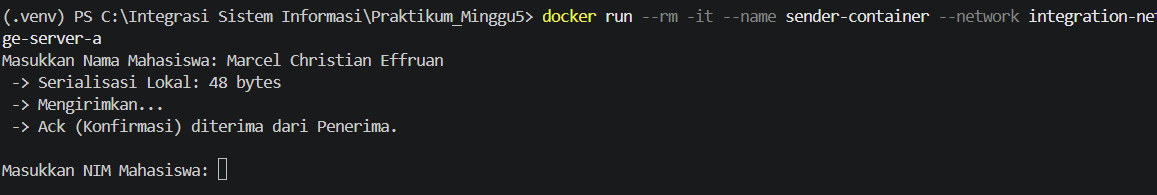

### 8.2 Terminal 1: Server B (Penerima)
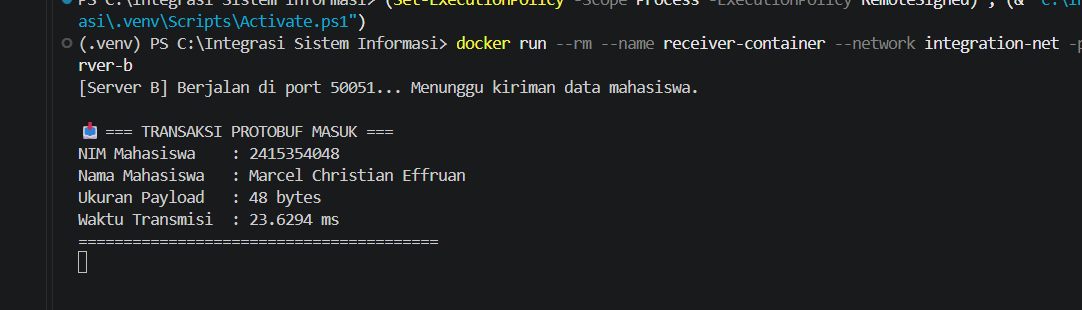

**Ringkasan hasil:**

| Parameter | Nilai |
|---|---|
| NIM terkirim | 2415354048 |
| Nama terkirim | Marcel Christian Effruan |
| Ukuran serialisasi di Server A | 48 bytes |
| Ukuran payload diterima di Server B | 48 bytes |
| Waktu transmisi (one-way latency) | 23,6294 ms |
| Konfirmasi (Ack) | Diterima |


## 9. Analisis
### 9.1 Mengapa payload 48 bytes?
Protobuf menyandikan tiap field sebagai pasangan *tag* dan *nilai*. Di sini kita hitung manual ukuran pesan `StudentRequest` untuk membuktikan angka 48 bytes dari hasil percobaan.

In [1]:
def varint(n: int) -> bytes:
    """Encode bilangan bulat tak-negatif sebagai varint protobuf."""
    out = bytearray()
    while True:
        b = n & 0x7F
        n >>= 7
        if n:
            out.append(b | 0x80)
        else:
            out.append(b)
            return bytes(out)

def field_string(num: int, s: str) -> bytes:
    data = s.encode("utf-8")
    return varint((num << 3) | 2) + varint(len(data)) + data      # wire type 2

def field_int64(num: int, v: int) -> bytes:
    return varint((num << 3) | 0) + varint(v)                      # wire type 0

nim  = "2415354048"
nama = "Marcel Christian Effruan"
ts   = 1791000000000000000   # contoh timestamp nanodetik (19 digit), sama orde dengan time.time_ns()

parts = {
    "student_id (field 1)":        field_string(1, nim),
    "student_name (field 2)":      field_string(2, nama),
    "sent_timestamp_ns (field 3)": field_int64(3, ts),
}
protobuf_bytes = b"".join(parts.values())

for k, v in parts.items():
    print(f"{k:30s}: {len(v):3d} bytes")
print("-" * 45)
print(f"{'TOTAL Protobuf':30s}: {len(protobuf_bytes):3d} bytes   (hasil praktikum: 48 bytes)")

student_id (field 1)          :  12 bytes
student_name (field 2)        :  26 bytes
sent_timestamp_ns (field 3)   :  10 bytes
---------------------------------------------
TOTAL Protobuf                :  48 bytes   (hasil praktikum: 48 bytes)


Rinciannya: NIM 10 karakter + 2 byte (tag dan panjang) = 12 byte; nama 24 karakter + 2 byte = 26 byte; timestamp 1 byte tag + 9 byte varint = 10 byte. Total **48 bytes**, sama dengan hasil pada Server A dan Server B.

*Catatan:* contoh pada job sheet menyebut 26 bytes untuk NIM `22010934` dan nama `Budi Santoso`. Dengan timestamp nanodetik yang selalu memakai 9 byte varint, ukuran sebenarnya 34 bytes, sehingga angka 26 bytes pada job sheet hanya ilustrasi.

### 9.2 Perbandingan dengan JSON dan XML
Data yang sama dikodekan dalam JSON dan XML untuk melihat perbedaan ukuran.

In [2]:
import json
import xml.etree.ElementTree as ET
import pandas as pd

data = {"student_id": nim, "student_name": nama, "sent_timestamp_ns": ts}

json_bytes = json.dumps(data, separators=(",", ":")).encode("utf-8")

root = ET.Element("StudentRequest")
for k, v in data.items():
    ET.SubElement(root, k).text = str(v)
xml_bytes = ET.tostring(root, encoding="utf-8")

df = pd.DataFrame({
    "Format": ["Protobuf (biner)", "JSON (kompak)", "XML"],
    "Ukuran (bytes)": [len(protobuf_bytes), len(json_bytes), len(xml_bytes)],
})
df["Relatif terhadap Protobuf"] = (df["Ukuran (bytes)"] / len(protobuf_bytes)).round(2).astype(str) + "x"
df["Hemat Protobuf (%)"] = ((1 - len(protobuf_bytes) / df["Ukuran (bytes)"]) * 100).round(1)
df

,Format,Ukuran (bytes),Relatif terhadap Protobuf,Hemat Protobuf (%)
0,Protobuf (biner),48,1.0x,0.0
1,JSON (kompak),109,2.27x,56.0
2,XML,179,3.73x,73.2


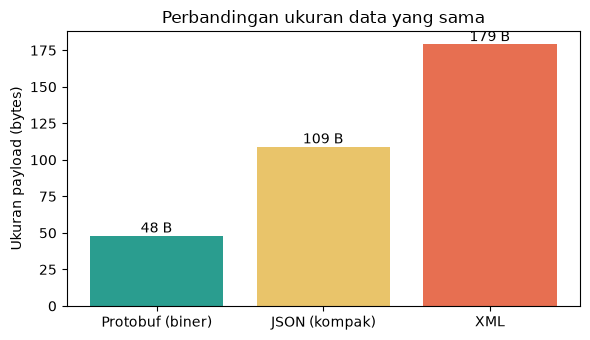

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(df["Format"], df["Ukuran (bytes)"], color=["#2a9d8f", "#e9c46a", "#e76f51"])
ax.bar_label(bars, fmt="%d B")
ax.set_ylabel("Ukuran payload (bytes)")
ax.set_title("Perbandingan ukuran data yang sama")
plt.tight_layout()
plt.show()

Hasilnya menunjukkan Protobuf menghasilkan payload paling kecil. Pada JSON dan XML, nama field ditulis ulang sebagai teks pada setiap pesan dan angka disimpan sebagai karakter ASCII. Pada Protobuf, nama field digantikan nomor field 1 byte, dan angka disimpan sebagai varint. Selisih ini makin berarti ketika jumlah pesan besar atau bandwidth terbatas.

### 9.3 Latensi
Server B mencatat waktu transmisi satu arah sebesar **23,6294 ms** pada pengiriman pertama. Nilai ini relatif besar karena:
- koneksi gRPC (HTTP/2) baru dibuka pada pemanggilan pertama;
- lalu lintas antar kontainer pada Docker Desktop di Windows melewati lapisan virtualisasi WSL2;
- selisih waktu dihitung dari `time.time_ns()` di dua kontainer berbeda, sehingga ikut mengandung overhead pembentukan koneksi.

Pengiriman berikutnya pada koneksi yang sama umumnya lebih cepat karena koneksi sudah terbentuk.

### 9.4 Peran file `.proto`
File `exchange.proto` adalah kontrak kaku. Pengirim dan penerima memakai stub hasil kompilasi dari skema yang sama, sehingga struktur dan tipe data pasti seragam. Perubahan skema harus dikompilasi ulang agar kedua sisi tetap kompatibel.

## 10. Kesimpulan
1. Pertukaran data biner antar dua kontainer Docker menggunakan Protobuf dan gRPC berhasil: Server B menerima NIM, nama, dan ukuran payload dengan benar, dan Server A menerima konfirmasi (Ack).
2. Ukuran pesan 48 bytes sama di sisi pengirim dan penerima, dan sesuai dengan perhitungan manual pengodean Protobuf.
3. Format biner Protobuf menghasilkan payload yang lebih kecil dibandingkan JSON dan XML untuk data yang sama.
4. Jaringan Docker (`integration-net`) memungkinkan komunikasi antar kontainer memakai nama kontainer, sehingga lingkungan server terisolasi namun tetap terhubung.
